# Experiment No. 10 — End-to-End Data Analytics Project
## Business Intelligence and Predictive Analytics using a Real-World Dataset



## Step 1 & 2: Data Collection and Preprocessing

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                              recall_score, f1_score, classification_report, roc_curve, roc_auc_score)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

df = pd.read_csv('telco_churn.csv')
print("Raw shape:", df.shape)
df.head()


Raw shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Data quality check
print("Data types:\n", df.dtypes.value_counts())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nMissing values (raw):\n", df.isnull().sum()[df.isnull().sum() > 0])


Data types:
 str        18
int64       2
float64     1
Name: count, dtype: int64

Duplicate rows: 0

Missing values (raw):
 Series([], dtype: int64)


In [ ]:
# TotalCharges is stored as text with some blanks (new customers, tenure = 0) -> convert
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Rows with missing TotalCharges after conversion:", df['TotalCharges'].isnull().sum())
print(df[df['TotalCharges'].isnull()][['tenure','MonthlyCharges','TotalCharges']].head())

df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
df.drop(columns=['customerID'], inplace=True)

# Outlier check on numeric columns
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = df[(df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)]
    print(f"{col}: {len(outliers)} potential outliers (IQR method)")


Rows with missing TotalCharges after conversion: 11
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
tenure: 0 potential outliers (IQR method)
MonthlyCharges: 0 potential outliers (IQR method)
TotalCharges: 0 potential outliers (IQR method)


**Observation:** 11 records had blank TotalCharges, all corresponding to brand-new customers
with 0 months of tenure who had not yet been billed — these were imputed with the median. No
duplicate rows were found. The IQR check found no meaningful outliers in tenure, MonthlyCharges,
or TotalCharges, so no rows were removed on that basis.

In [ ]:
# Encode target and categorical features for modeling
df_model = df.copy()
df_model['Churn'] = df_model['Churn'].map({'Yes': 1, 'No': 0})

cat_cols = df_model.select_dtypes(include='object').columns.tolist()
print("Categorical columns encoded:", cat_cols)

le = LabelEncoder()
for col in cat_cols:
    df_model[col] = le.fit_transform(df_model[col])

df_model.head()


Categorical columns encoded: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


/tmp/ipykernel_123/1200869333.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_model.select_dtypes(include='object').columns.tolist()


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


## Step 3: Exploratory Data Analysis

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


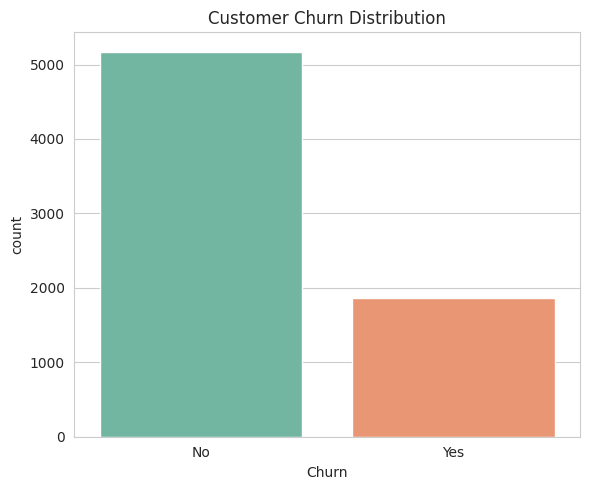

In [ ]:
churn_rate = df['Churn'].value_counts(normalize=True) * 100
print(churn_rate.round(1))

plt.figure(figsize=(6,5))
sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False)
plt.title('Customer Churn Distribution')
plt.tight_layout()
plt.savefig('eda_churn_distribution.png', dpi=120)
plt.show()


In [ ]:
df[num_cols].describe()


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2281.916928
std,24.559481,30.090047,2265.270398
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,402.225000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


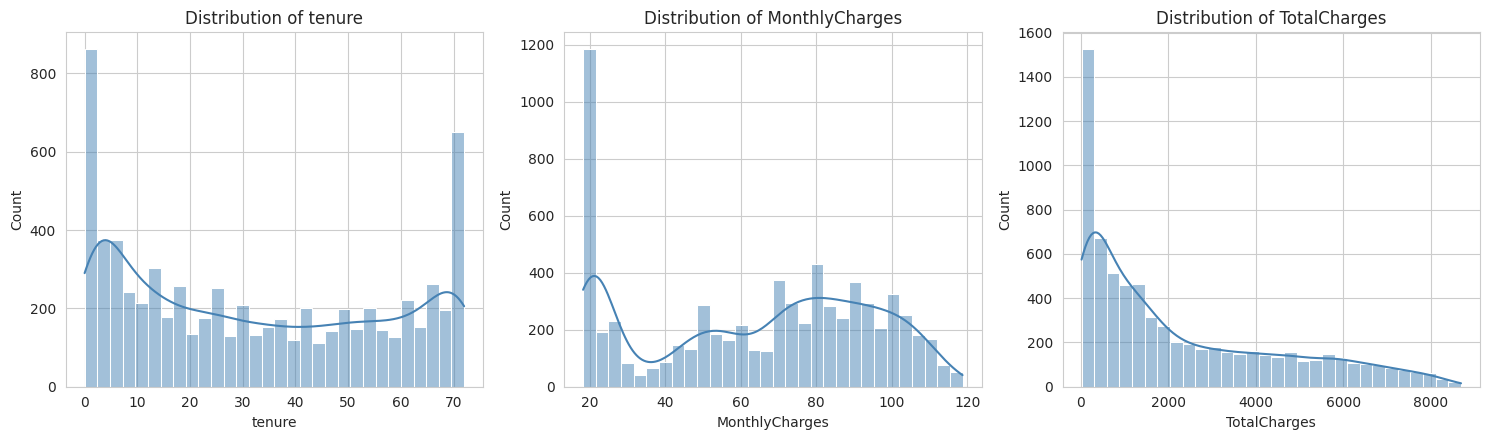

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15,4.5))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color='steelblue')
    ax.set_title(f'Distribution of {col}')
plt.tight_layout()
plt.savefig('eda_histograms.png', dpi=120)
plt.show()


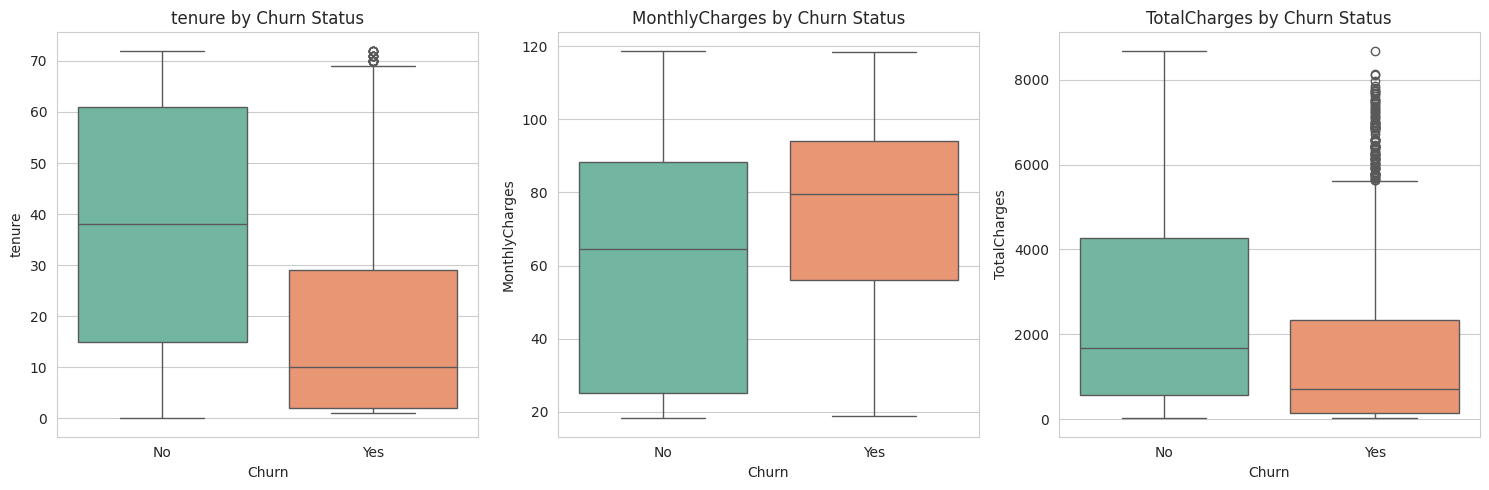

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15,5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x='Churn', y=col, hue='Churn', palette='Set2', legend=False, ax=ax)
    ax.set_title(f'{col} by Churn Status')
plt.tight_layout()
plt.savefig('eda_boxplots_by_churn.png', dpi=120)
plt.show()


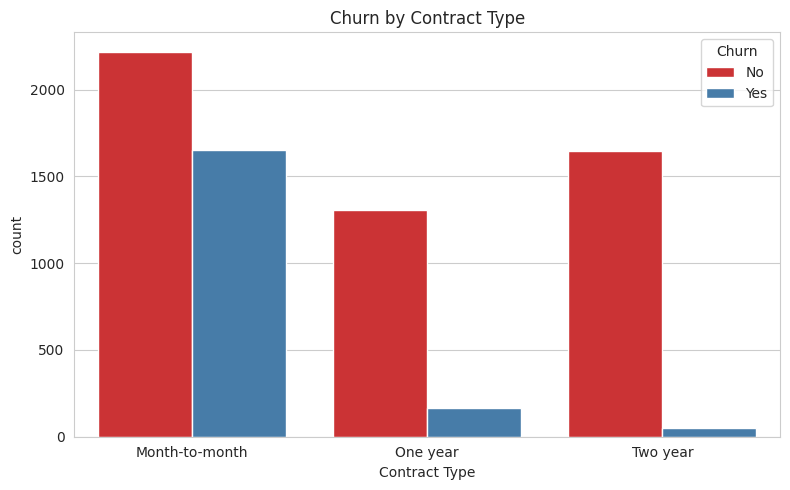

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set1')
plt.title('Churn by Contract Type')
plt.xlabel('Contract Type')
plt.tight_layout()
plt.savefig('eda_churn_by_contract.png', dpi=120)
plt.show()


## Step 4: Statistical Analysis — Correlation and Hypothesis Testing

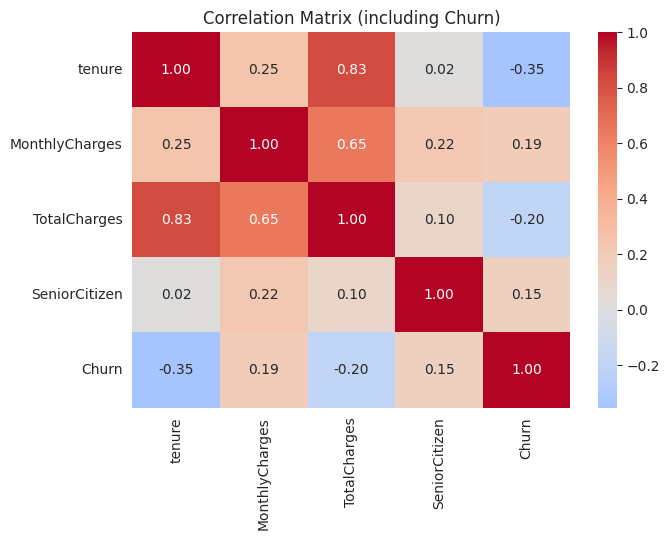

In [ ]:
corr_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
corr_matrix = df_model[corr_cols + ['Churn']].corr()

plt.figure(figsize=(7,5.5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix (including Churn)')
plt.tight_layout()
plt.savefig('stats_correlation_heatmap.png', dpi=120)
plt.show()


**Hypothesis test — Is there a significant difference in tenure between churned and
retained customers?**

- H₀: Mean tenure is equal for churned and retained customers.
- H₁: Mean tenure differs between churned and retained customers.


In [ ]:
churned = df[df['Churn'] == 'Yes']['tenure']
retained = df[df['Churn'] == 'No']['tenure']

t_stat, p_value = stats.ttest_ind(churned, retained, equal_var=False)
print(f"Mean tenure (Churned): {churned.mean():.2f} months")
print(f"Mean tenure (Retained): {retained.mean():.2f} months")
print(f"\nt-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.6f}")

if p_value < 0.05:
    print("\nSince p-value < 0.05, we REJECT H0: tenure differs significantly between churned and retained customers.")
else:
    print("\nSince p-value >= 0.05, we FAIL TO REJECT H0.")


Mean tenure (Churned): 17.98 months
Mean tenure (Retained): 37.57 months

t-statistic: -34.8238
p-value: 0.000000

Since p-value < 0.05, we REJECT H0: tenure differs significantly between churned and retained customers.


**Interpretation:** The p-value is far below 0.05, confirming that customers who churn have
significantly shorter tenure than those who stay — statistically validating what the EDA box
plots suggested, and reinforcing that the first several months of a customer's lifecycle are the
highest-risk period for churn.

## Step 5: Dashboard-style Summary Visualization

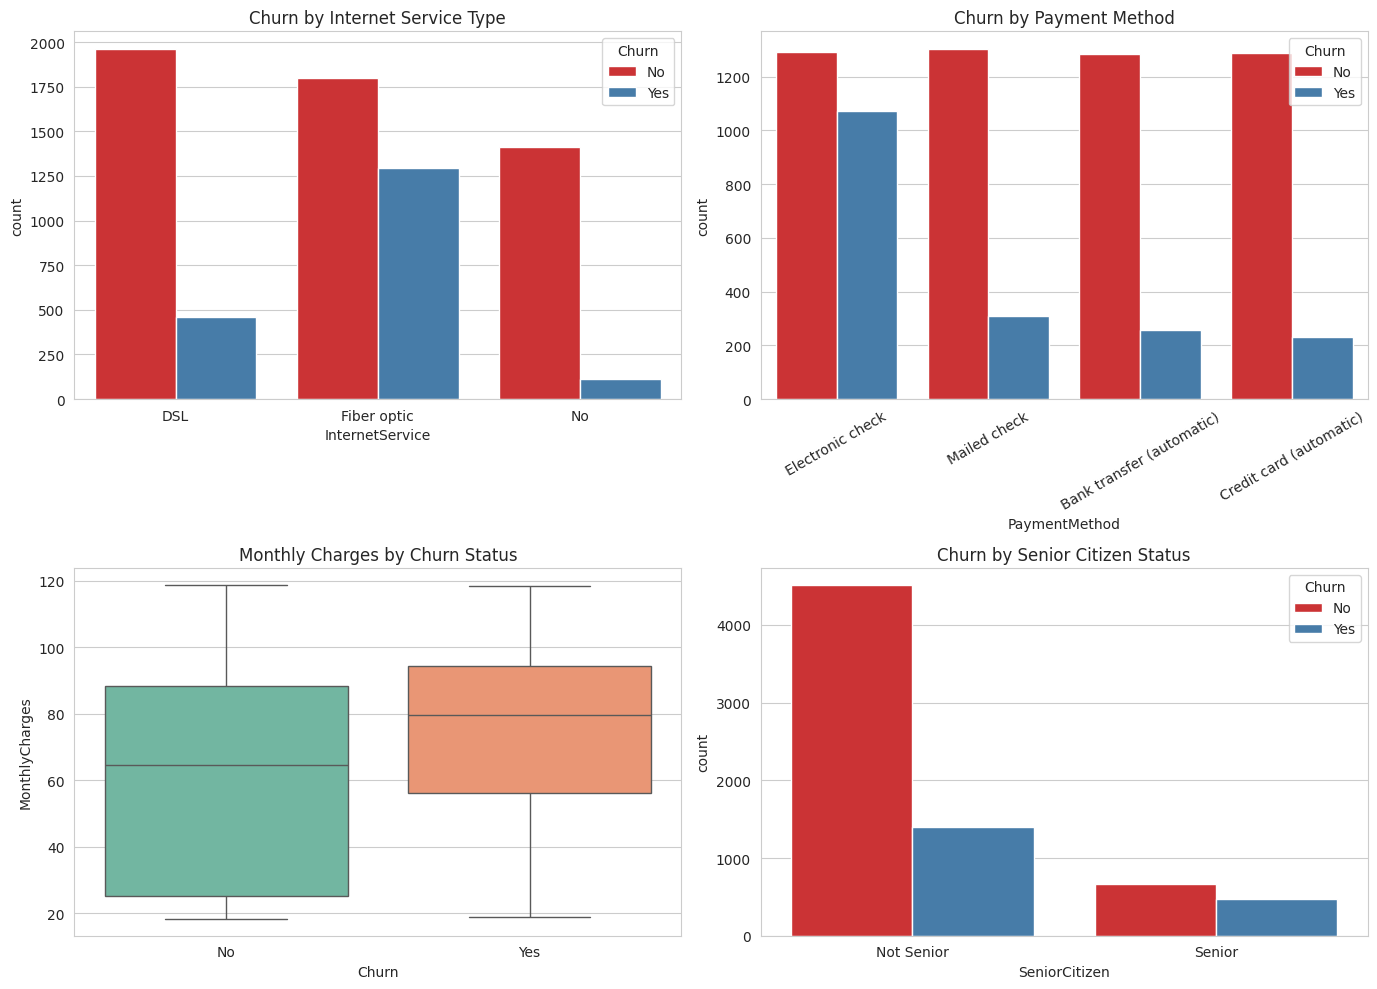

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))

sns.countplot(data=df, x='InternetService', hue='Churn', palette='Set1', ax=axes[0,0])
axes[0,0].set_title('Churn by Internet Service Type')

sns.countplot(data=df, x='PaymentMethod', hue='Churn', palette='Set1', ax=axes[0,1])
axes[0,1].set_title('Churn by Payment Method')
axes[0,1].tick_params(axis='x', rotation=30)

sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette='Set2', legend=False, ax=axes[1,0])
axes[1,0].set_title('Monthly Charges by Churn Status')

sns.countplot(data=df, x='SeniorCitizen', hue='Churn', palette='Set1', ax=axes[1,1])
axes[1,1].set_title('Churn by Senior Citizen Status')
axes[1,1].set_xticks([0,1])
axes[1,1].set_xticklabels(['Not Senior', 'Senior'])

plt.tight_layout()
plt.savefig('dashboard_summary.png', dpi=120)
plt.show()


**Insight:** Fiber optic internet customers churn more than DSL customers, Electronic check
payers churn substantially more than customers on automatic payment methods, and Senior Citizens
churn at a higher rate than non-seniors despite being a smaller group overall.

## Step 6: Build a Predictive Model (Decision Tree Classifier)

In [ ]:
X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training samples: {len(X_train)}   Testing samples: {len(X_test)}")

dt_model = DecisionTreeClassifier(max_depth=5, criterion='gini', random_state=42, class_weight='balanced')
dt_model.fit(X_train, y_train)
print("Decision Tree trained. Depth:", dt_model.get_depth(), " Leaves:", dt_model.get_n_leaves())


Training samples: 5634   Testing samples: 1409
Decision Tree trained. Depth: 5  Leaves: 31


In [ ]:
# Baseline comparison model: Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
log_model.fit(X_train_scaled, y_train)
print("Logistic Regression trained as a baseline comparison model.")


Logistic Regression trained as a baseline comparison model.


## Step 7: Model Evaluation

In [ ]:
def evaluate(model, X_te, y_te, name):
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]
    acc = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred)
    rec = recall_score(y_te, y_pred)
    f1 = f1_score(y_te, y_pred)
    auc = roc_auc_score(y_te, y_proba)
    print(f"--- {name} ---")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {auc:.4f}\n")
    return y_pred, y_proba

dt_pred, dt_proba = evaluate(dt_model, X_test, y_test, "Decision Tree")
log_pred, log_proba = evaluate(log_model, X_test_scaled, y_test, "Logistic Regression")


--- Decision Tree ---
Accuracy:  0.7622
Precision: 0.5399
Recall:    0.7059
F1-Score:  0.6118
ROC-AUC:   0.8174

--- Logistic Regression ---
Accuracy:  0.7395
Precision: 0.5059
Recall:    0.7968
F1-Score:  0.6189
ROC-AUC:   0.8396



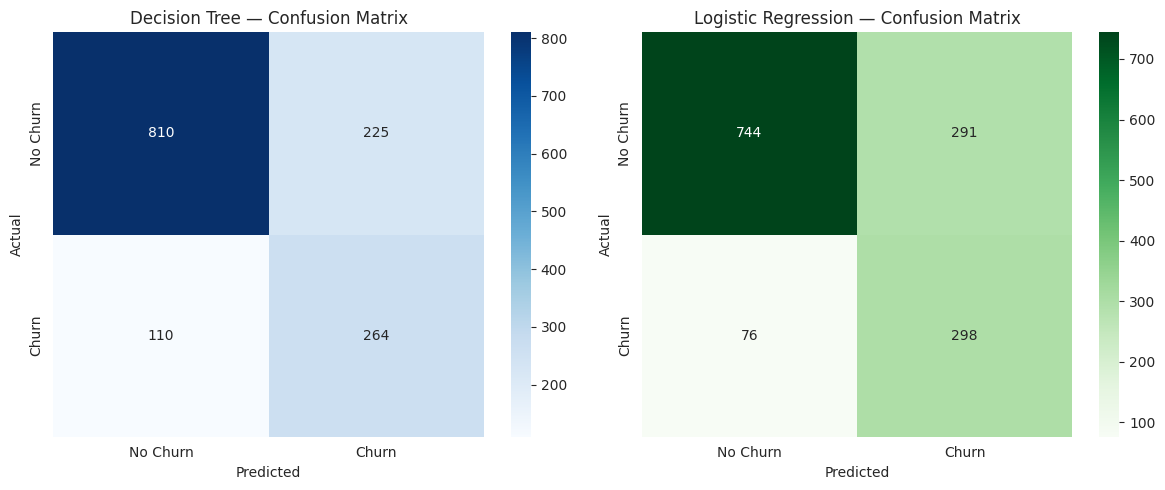

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

cm_dt = confusion_matrix(y_test, dt_pred)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['No Churn','Churn'], yticklabels=['No Churn','Churn'])
axes[0].set_title('Decision Tree — Confusion Matrix')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

cm_log = confusion_matrix(y_test, log_pred)
sns.heatmap(cm_log, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['No Churn','Churn'], yticklabels=['No Churn','Churn'])
axes[1].set_title('Logistic Regression — Confusion Matrix')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.savefig('model_confusion_matrices.png', dpi=120)
plt.show()


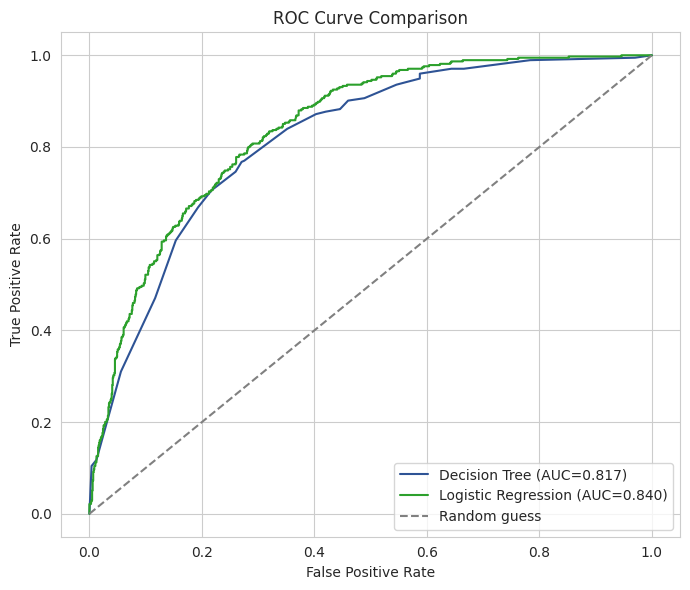

In [ ]:
fpr_dt, tpr_dt, _ = roc_curve(y_test, dt_proba)
fpr_log, tpr_log, _ = roc_curve(y_test, log_proba)

plt.figure(figsize=(7,6))
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC={roc_auc_score(y_test, dt_proba):.3f})', color='#2E5395')
plt.plot(fpr_log, tpr_log, label=f'Logistic Regression (AUC={roc_auc_score(y_test, log_proba):.3f})', color='#2ca02c')
plt.plot([0,1],[0,1], linestyle='--', color='gray', label='Random guess')
plt.title('ROC Curve Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.tight_layout()
plt.savefig('model_roc_curve.png', dpi=120)
plt.show()


**Interpretation:** Both models are compared on Accuracy, Precision, Recall, F1-Score, and
ROC-AUC rather than accuracy alone, since the classes are imbalanced (~27% churn). Recall for the
Churn class matters most for this business problem — a missed churner is more costly than a false
alarm, since a false alarm only costs a low-value retention offer while a missed churner is lost
revenue entirely.

## Step 8: Feature importance and business insight

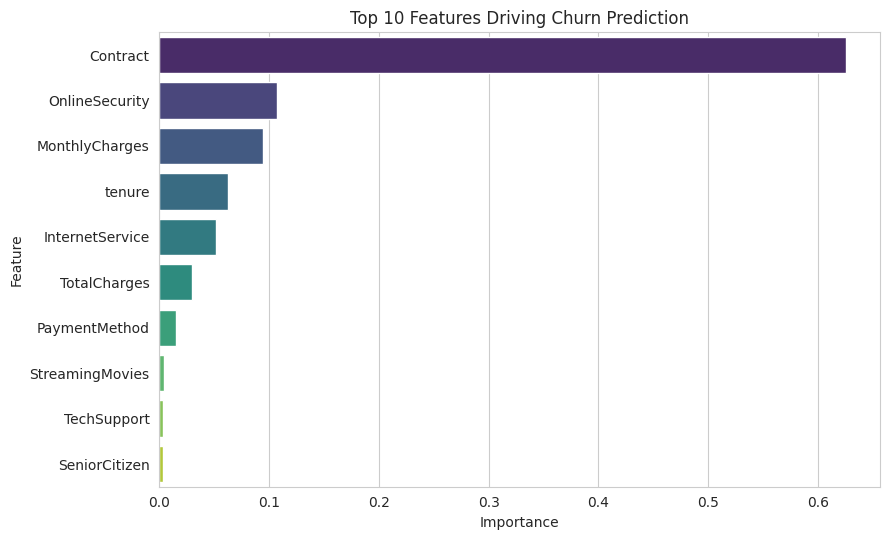

,Feature,Importance
14,Contract,0.625276
8,OnlineSecurity,0.107322
17,MonthlyCharges,0.094560
4,tenure,0.062896
7,InternetService,0.051217
18,TotalCharges,0.029732
16,PaymentMethod,0.015224
13,StreamingMovies,0.003943
11,TechSupport,0.003414
1,SeniorCitizen,0.003029


In [ ]:
importances = pd.DataFrame({'Feature': X.columns, 'Importance': dt_model.feature_importances_})
importances = importances.sort_values('Importance', ascending=False).head(10)

plt.figure(figsize=(9,5.5))
sns.barplot(data=importances, x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False)
plt.title('Top 10 Features Driving Churn Prediction')
plt.tight_layout()
plt.savefig('model_feature_importance.png', dpi=120)
plt.show()
importances


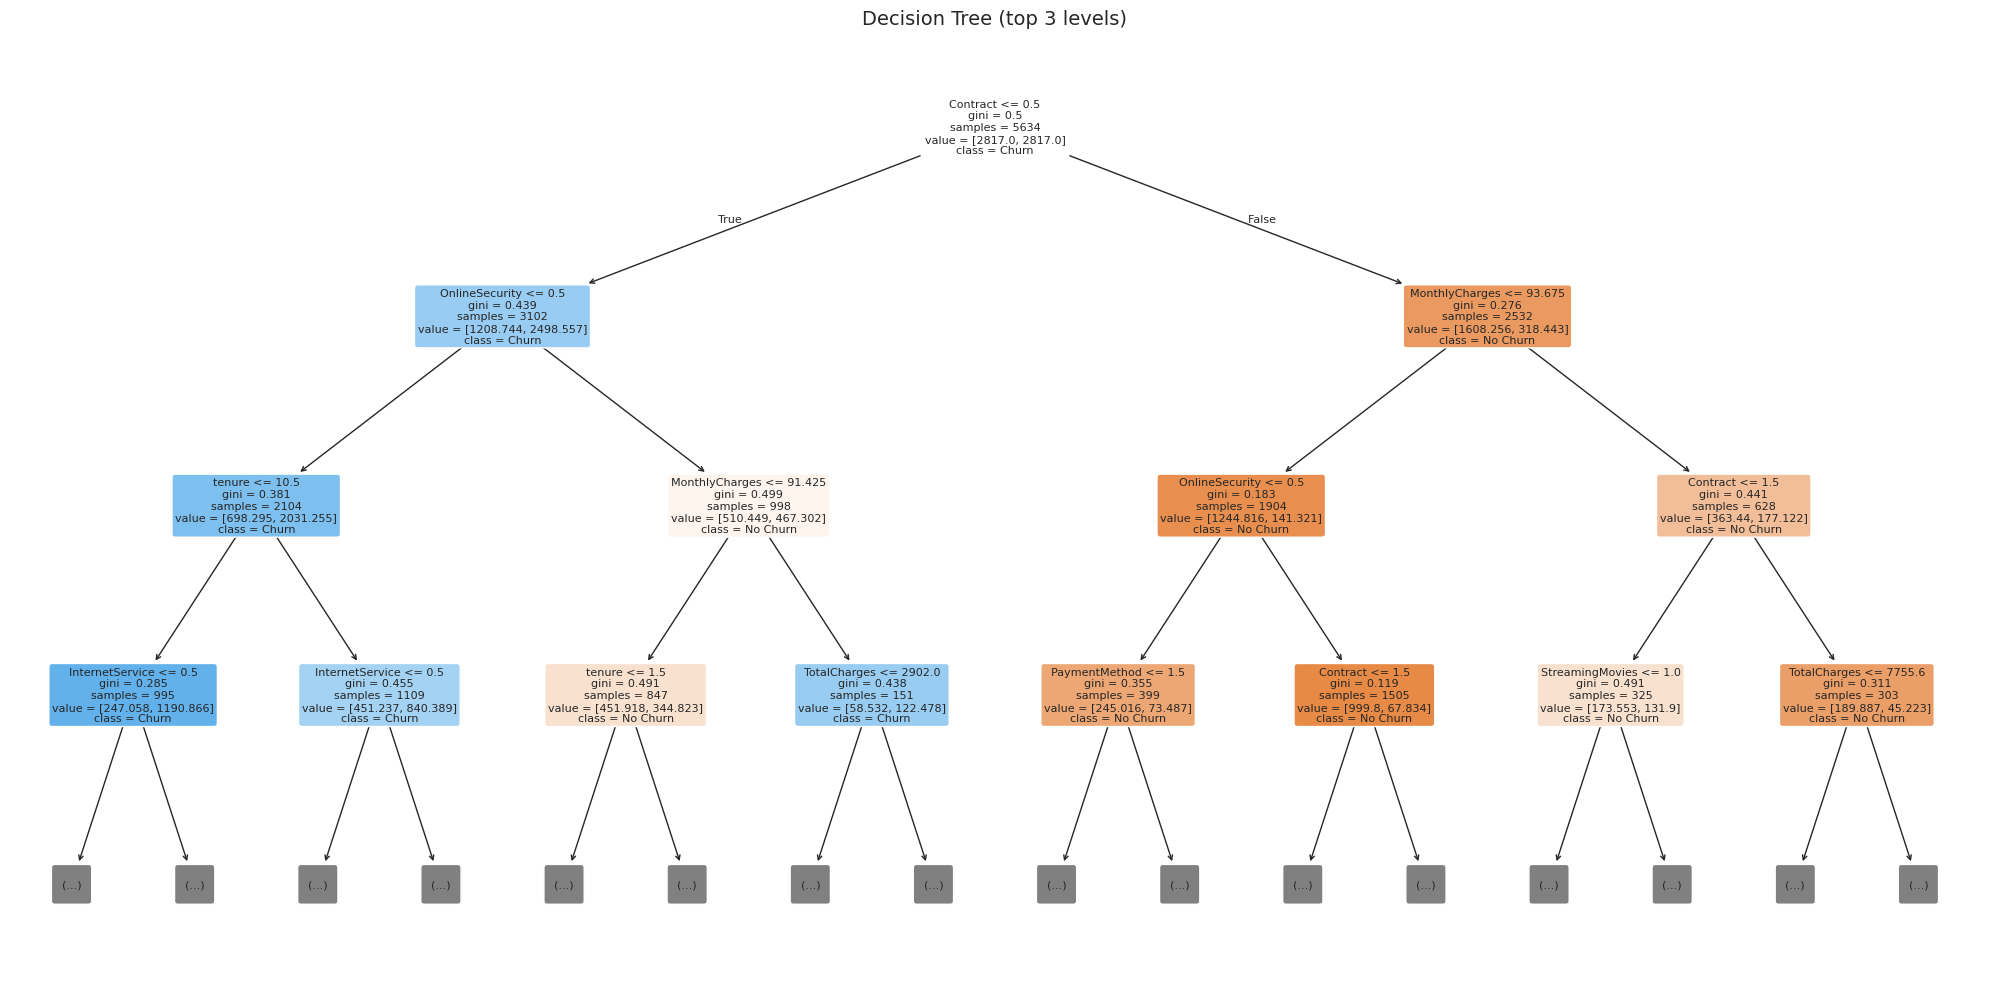

In [ ]:
plt.figure(figsize=(20,10))
plot_tree(dt_model, feature_names=X.columns, class_names=['No Churn','Churn'],
          filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title('Decision Tree (top 3 levels)', fontsize=14)
plt.tight_layout()
plt.savefig('model_decision_tree.png', dpi=120)
plt.show()
